# Task 1: Dataset Exploration and Understanding
Facial Feature Classification Challenge (ENGE707). Set the three paths in the next cell, then run all cells top to bottom. No Kaggle needed.

In [2]:
TRAIN_DIR = r"C:\Users\matty\Documents\GitHub\2026_S1_-W102-_cLocked-In\ENSE707_Week2_Lab_23206450\Kaggle_Competition_23206450\train\train"
TEST_DIR = r"C:\Users\matty\Documents\GitHub\2026_S1_-W102-_cLocked-In\ENSE707_Week2_Lab_23206450\Kaggle_Competition_23206450\test\test"
LABELS_CSV = r"C:\Users\matty\Documents\GitHub\2026_S1_-W102-_cLocked-In\ENSE707_Week2_Lab_23206450\Kaggle_Competition_23206450\train_labels.csv"

SEED = 42
BLUR_SAMPLE = 2000

In [4]:
import hashlib, os, random
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

random.seed(SEED); np.random.seed(SEED)
EXT = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

def list_images(root):
    return [os.path.join(d, f) for d, _, fs in os.walk(root)
            for f in fs if os.path.splitext(f)[1].lower() in EXT]

def norm(x):
    """'00012' and '12' map to the same key."""
    x = os.path.splitext(str(x))[0]
    return x.lstrip("0") or "0"

def md5(path):
    h = hashlib.md5()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()

def sharpness(path):
    """Variance of a Laplacian on a 128x128 grayscale copy. Lower means blurrier."""
    g = np.asarray(Image.open(path).convert("L").resize((128, 128)), dtype=np.float32)
    lap = 4 * g[1:-1, 1:-1] - g[:-2, 1:-1] - g[2:, 1:-1] - g[1:-1, :-2] - g[1:-1, 2:]
    return float(lap.var())

## 1. Structure of the training and test data

In [5]:
def build_train_table():
    paths = list_images(TRAIN_DIR)
    if LABELS_CSV:
        lab = pd.read_csv(LABELS_CSV)
        id_col = lab.columns[0]
        cls_col = next(c for c in lab.columns if c.lower() in ("class", "label"))
        by_stem = {norm(os.path.basename(p)): p for p in paths}
        by_name = {os.path.basename(p): p for p in paths}
        rows = []
        for i, c in zip(lab[id_col].astype(str), lab[cls_col]):
            rows.append((by_name.get(i) or by_stem.get(norm(i)), c))
        df = pd.DataFrame(rows, columns=["path", "label"])
        if df["path"].isna().sum():
            print("WARNING: labelled ids with no image file:", int(df["path"].isna().sum()))
        return df.dropna()
    return pd.DataFrame({"path": paths, "label": [os.path.basename(os.path.dirname(p)) for p in paths]})

train = build_train_table()
test_paths = list_images(TEST_DIR)
print(f"Training images: {len(train)}   Test images: {len(test_paths)}")
files_all = {norm(os.path.basename(p)) for p in list_images(TRAIN_DIR)}
labelled = {norm(os.path.basename(p)) for p in train["path"]}
print("Image files with no label:", len(files_all - labelled), "  Labels with no image file:", len(labelled - files_all))
print("Classes:", sorted(train["label"].unique()))

Training images: 63660   Test images: 29443
Image files with no label: 0   Labels with no image file: 0
Classes: ['CatEye', 'CatFace', 'CatMouth', 'CatNose', 'DogEye', 'DogFace', 'DogMouth', 'DogNose']


## 2. Images per class and balance

,images,share_%
label,,
CatEye,13884,21.81
CatFace,6942,10.90
CatMouth,6942,10.90
CatNose,6942,10.90
DogEye,11580,18.19
DogFace,5790,9.10
DogMouth,5790,9.10
DogNose,5790,9.10


Largest / smallest ratio: 2.40  (largest CatEye = 13884, smallest DogFace = 5790)


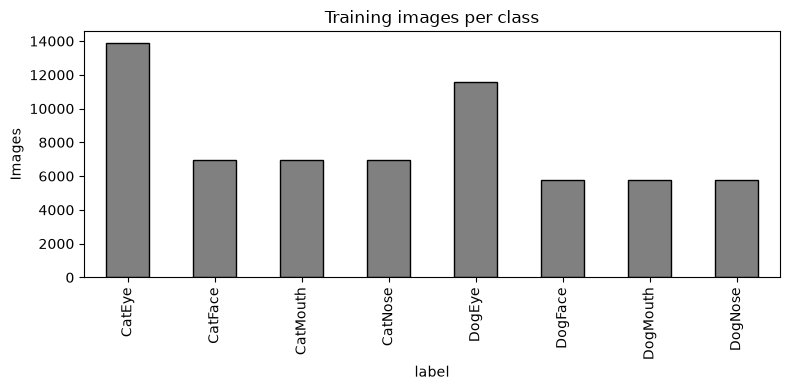

In [10]:
counts = train["label"].value_counts().sort_index()
summary = pd.DataFrame({"images": counts, "share_%": (100 * counts / counts.sum()).round(2)})
display(summary)
print(f"Largest / smallest ratio: {counts.max() / counts.min():.2f}  "
      f"(largest {counts.idxmax()} = {counts.max()}, smallest {counts.idxmin()} = {counts.min()})")

plt.figure(figsize=(8, 4))
counts.plot(kind="bar", color="gray", edgecolor="black")
plt.ylabel("Images"); plt.title("Training images per class"); plt.tight_layout(); plt.show()

## 3. Sample images from each class

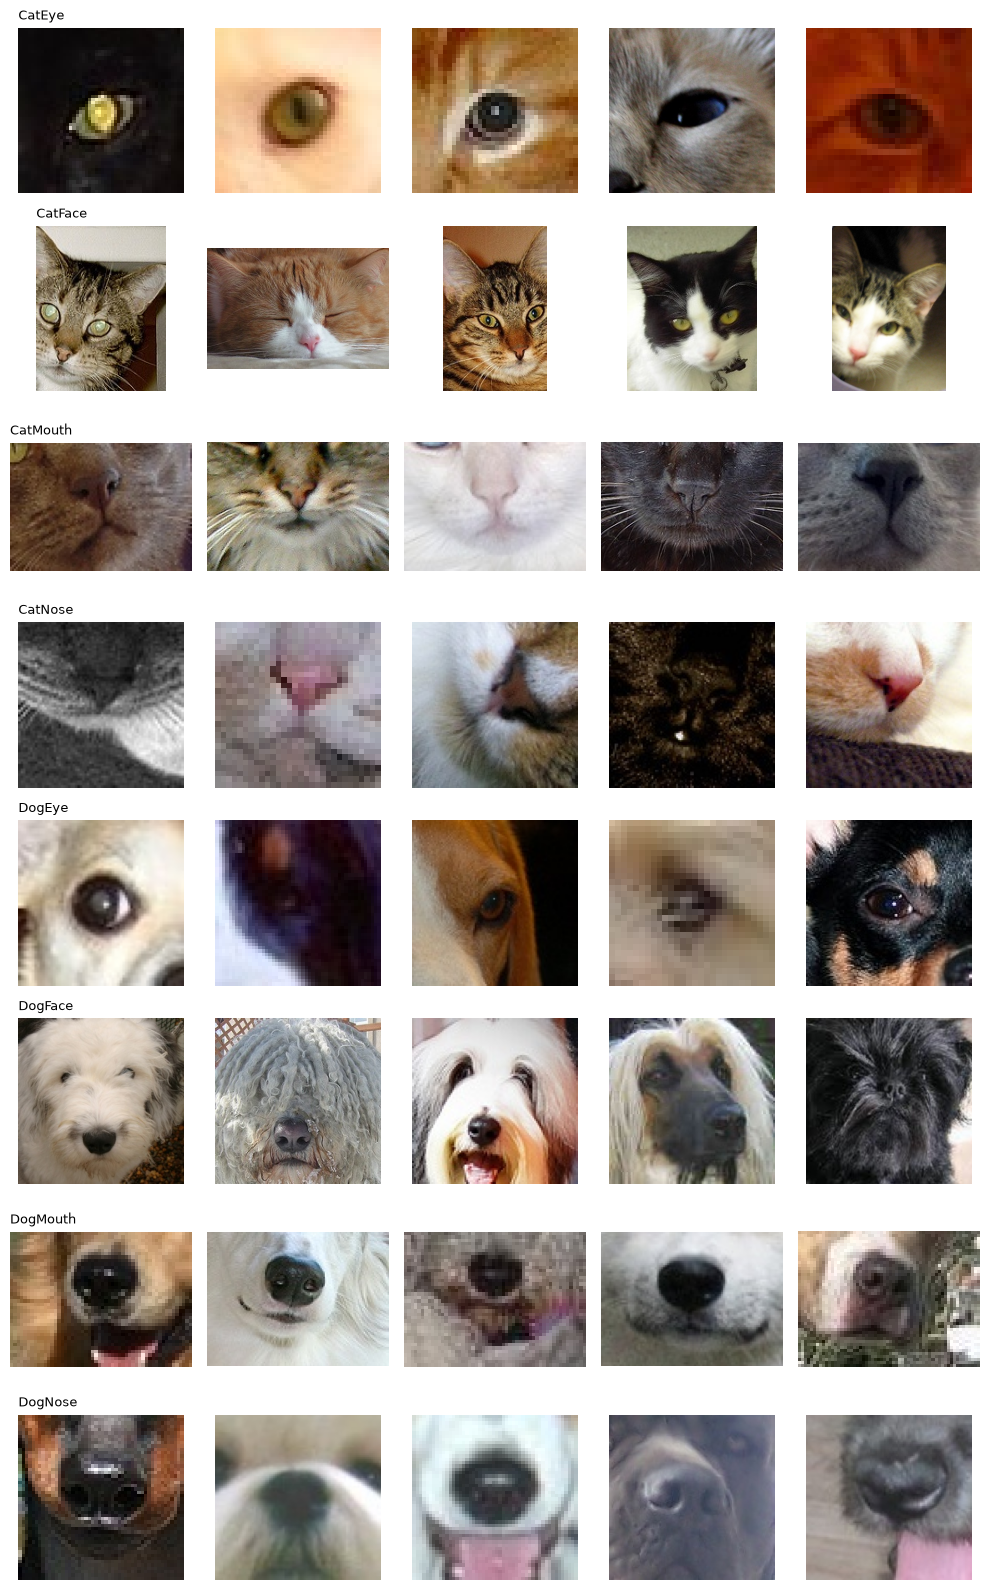

In [11]:
classes = list(counts.index)
fig, axes = plt.subplots(len(classes), 5, figsize=(10, 2 * len(classes)))
for r, c in enumerate(classes):
    picks = train[train["label"] == c].sample(min(5, counts[c]), random_state=SEED)["path"].tolist()
    for k in range(5):
        ax = axes[r][k]; ax.axis("off")
        if k < len(picks):
            ax.imshow(Image.open(picks[k]).convert("RGB"))
        if k == 0:
            ax.set_title(c, loc="left", fontsize=9)
plt.tight_layout(); plt.show()

## 4. Data quality: image sizes and corrupted file

Corrupted or unreadable training files: 0
Distinct image sizes: 7861   most common: [((40, 40), 1062), ((48, 48), 1051), ((42, 42), 1050), ((38, 38), 1002), ((44, 44), 1002)]
Width 4 to 2219,  height 4 to 2219


,w,h
label,,
CatEye,68.0,68.0
CatFace,182.0,215.0
CatMouth,114.0,80.0
CatNose,68.0,68.0
DogEye,62.0,62.0
DogFace,155.0,155.0
DogMouth,104.0,77.0
DogNose,62.0,62.0


Test images read: 29443 of 29443;  distinct sizes: 7786   most common: [((40, 40), 503), ((50, 50), 402), ((80, 80), 370), ((30, 30), 349), ((60, 60), 343)]
Test width 8 to 1832,  height 9 to 1978
TRAIN: shortest side median 78px, 5th pct 30px, min 4, max 2219;  under 32px: 4130 (6.5%),  under 64px: 23698 (37.2%),  under 112px: 44172 (69.4%)
TEST : shortest side median 77px, 5th pct 28px, min 8, max 1832;  under 32px: 2422 (8.2%),  under 64px: 11897 (40.4%),  under 112px: 20801 (70.6%)


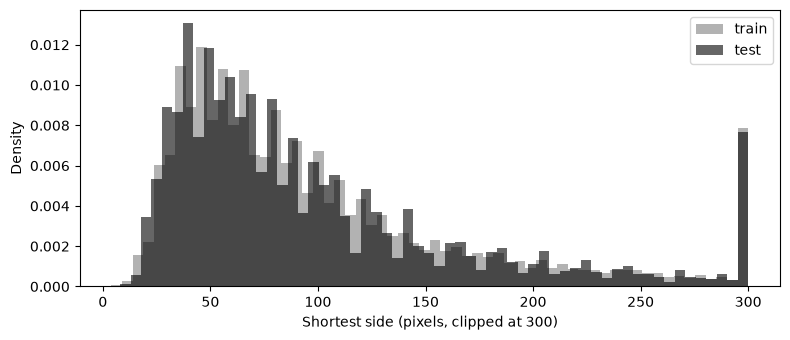

In [12]:
recs = []
for p, lab in zip(train["path"], train["label"]):
    rec = {"path": p, "label": lab, "w": None, "h": None, "corrupt": False, "md5": None}
    try:
        with Image.open(p) as im:
            rec["w"], rec["h"] = im.size
            im.verify()
        rec["md5"] = md5(p)
    except Exception:
        rec["corrupt"] = True
    recs.append(rec)
q = pd.DataFrame(recs)
ok = q[~q["corrupt"]].astype({"w": int, "h": int})

print("Corrupted or unreadable training files:", int(q["corrupt"].sum()))
sizes = Counter(zip(ok["w"], ok["h"]))
print(f"Distinct image sizes: {len(sizes)}   most common: {sizes.most_common(5)}")
print(f"Width {ok['w'].min()} to {ok['w'].max()},  height {ok['h'].min()} to {ok['h'].max()}")
display(ok.groupby("label")[["w", "h"]].median())

test_sizes = []
for p in test_paths:
    try:
        with Image.open(p) as im:
            test_sizes.append(im.size)
    except Exception:
        pass
tw = np.array([a for a, b in test_sizes]); th = np.array([b for a, b in test_sizes])
tsz = Counter(test_sizes)
print(f"Test images read: {len(test_sizes)} of {len(test_paths)};  distinct sizes: {len(tsz)}   most common: {tsz.most_common(5)}")
print(f"Test width {tw.min()} to {tw.max()},  height {th.min()} to {th.max()}")

def short_side_summary(w, h, name):
    sd = np.minimum(w, h)
    print(f"{name}: shortest side median {np.median(sd):.0f}px, 5th pct {np.percentile(sd, 5):.0f}px, min {sd.min()}, max {sd.max()};  "
          f"under 32px: {(sd < 32).sum()} ({100 * (sd < 32).mean():.1f}%),  under 64px: {(sd < 64).sum()} ({100 * (sd < 64).mean():.1f}%),  "
          f"under 112px: {(sd < 112).sum()} ({100 * (sd < 112).mean():.1f}%)")

short_side_summary(ok["w"].values, ok["h"].values, "TRAIN")
short_side_summary(tw, th, "TEST ")

plt.figure(figsize=(8, 3.5))
plt.hist(np.clip(np.minimum(ok["w"].values, ok["h"].values), 0, 300), bins=60, alpha=0.6, density=True, label="train", color="gray")
plt.hist(np.clip(np.minimum(tw, th), 0, 300), bins=60, alpha=0.6, density=True, label="test", color="black")
plt.xlabel("Shortest side (pixels, clipped at 300)"); plt.ylabel("Density"); plt.legend(); plt.tight_layout(); plt.show()

## 4b. Image size as a class signal

In [13]:
ok["short"] = np.minimum(ok["w"], ok["h"])
ok["aspect"] = ok["w"] / ok["h"]
by_class = ok.groupby("label").agg(
    median_w=("w", "median"), median_h=("h", "median"),
    median_shortest_side=("short", "median"),
    pct_under_64px=("short", lambda s: round(100 * (s < 64).mean(), 1)),
    median_aspect=("aspect", "median"))
display(by_class)
print(f"Square images (aspect ratio within 2% of 1): {100 * (abs(ok['aspect'] - 1) < 0.02).mean():.1f}%")
try:
    from sklearn.tree import DecisionTreeClassifier
    from sklearn.model_selection import cross_val_score
    acc = cross_val_score(DecisionTreeClassifier(max_depth=8, random_state=SEED),
                          ok[["w", "h"]].values, ok["label"], cv=5, scoring="accuracy").mean()
    print(f"Accuracy from image width and height alone (5-fold): {acc:.4f}   "
          f"majority-class baseline: {ok['label'].value_counts(normalize=True).max():.4f}")
except ImportError:
    print("scikit-learn not installed, skipping the size-only baseline")

,median_w,median_h,median_shortest_side,pct_under_64px,median_aspect
label,,,,,
CatEye,68.0,68.0,68.0,45.6,1.000000
CatFace,182.0,215.0,178.0,4.7,0.827823
CatMouth,114.0,80.0,80.0,34.9,1.419355
CatNose,68.0,68.0,68.0,45.6,1.000000
DogEye,62.0,62.0,62.0,52.5,1.000000
DogFace,155.0,155.0,155.0,2.5,1.000000
DogMouth,104.0,77.0,77.0,37.7,1.353846
DogNose,62.0,62.0,62.0,52.5,1.000000


Square images (aspect ratio within 2% of 1): 69.0%
Accuracy from image width and height alone (5-fold): 0.4579   majority-class baseline: 0.2181


## 5. Data quality: duplicates

In [14]:
dup = ok[ok.duplicated("md5", keep=False)]
print(f"Exact duplicate files in training: {len(dup)} images in {dup['md5'].nunique()} groups")
if len(dup):
    conflict = int((dup.groupby("md5")["label"].nunique() > 1).sum())
    print("Duplicate groups with conflicting labels:", conflict)
    for _, g in list(dup.groupby("md5"))[:5]:
        print("  e.g.", [os.path.basename(p) for p in g["path"]], g["label"].iloc[0])

test_hashes = set()
for p in test_paths:
    try:
        test_hashes.add(md5(p))
    except Exception:
        pass
print("Training images identical to a test image:", int(ok["md5"].isin(test_hashes).sum()))

Exact duplicate files in training: 30 images in 15 groups
Duplicate groups with conflicting labels: 0
  e.g. ['30201.jpg', '50179.jpg'] DogEye
  e.g. ['03926.jpg', '56008.jpg'] CatEye
  e.g. ['49150.jpg', '55761.jpg'] DogEye
  e.g. ['35039.jpg', '55965.jpg'] DogFace
  e.g. ['45625.jpg', '54078.jpg'] DogFace
Training images identical to a test image: 0


## 6. Data quality: blur

Sharpness on 2000 sampled images: median 211.0, 5th percentile 7.3, min 1.8
Median sharpness, shortest side under 48px: 17.9 (n=431);  48px or more: 379.2 (n=1569)


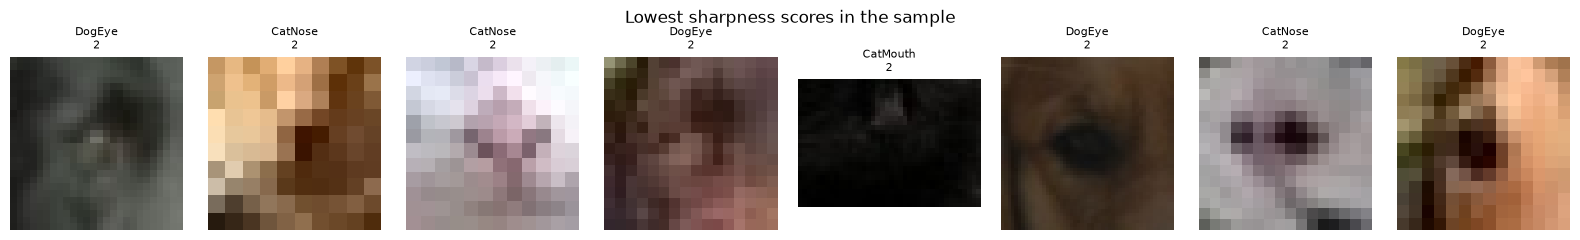

In [15]:
sample = ok.sample(min(BLUR_SAMPLE, len(ok)), random_state=SEED).copy()
sample["sharp"] = [sharpness(p) for p in sample["path"]]
print(f"Sharpness on {len(sample)} sampled images: median {sample['sharp'].median():.1f}, "
      f"5th percentile {sample['sharp'].quantile(0.05):.1f}, min {sample['sharp'].min():.1f}")

sample["short"] = np.minimum(sample["w"], sample["h"])
small, large = sample[sample["short"] < 48], sample[sample["short"] >= 48]
print(f"Median sharpness, shortest side under 48px: {small['sharp'].median():.1f} (n={len(small)});  48px or more: {large['sharp'].median():.1f} (n={len(large)})")

worst = sample.sort_values("sharp").head(8)
fig, axes = plt.subplots(1, 8, figsize=(16, 2.4))
for ax, (_, r) in zip(axes, worst.iterrows()):
    ax.imshow(Image.open(r["path"]).convert("RGB")); ax.axis("off")
    ax.set_title(f"{r['label']}\n{r['sharp']:.0f}", fontsize=8)
plt.suptitle("Lowest sharpness scores in the sample"); plt.tight_layout(); plt.show()

## 7. How the dataset will be used (for the report)
The labeled images are split into train and validation sets using a stratified split to keep the same proportion per class in each set, with a fixed random seed. I fit the model on the train set and use the validation set to spot when the model overfits and to weigh up design choices. Data augmentation is applied to the training set only. The test images do not have labels and are only used to produce predictions for the Kaggle submission (image_id, class). Duplicates are removed or forced to be in the same set to avoid a boosted validation score.